# Листок № 4. Классическое, статистическое, геометрическое определение вероятности
Условия взяты из `Практические занятия Листок 4 .pdf` (в шапке самого файла напечатано «Листок № 5», задачи имеют номера 4.x). Ко всем задачам с числовым ответом построен график относительной частоты $\hat p(A)=N(A)/N$.

In [1]:
%matplotlib inline
from fractions import Fraction as F
from math import comb
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import quad
rng = np.random.default_rng(2026)

def freq_plot(events, exact, title, fname=None, skip=500):
    '''Относительная частота события в зависимости от числа опытов N. Возвращает оценку.'''
    events = np.asarray(events,bool); N = events.size
    p = np.cumsum(events)/np.arange(1,N+1)
    fig,ax = plt.subplots(figsize=(8,2.8))
    ax.plot(np.arange(skip,N+1),p[skip-1:],'b',lw=.8,label='$\\hat p(A)$')
    if exact is not None: ax.axhline(exact,color='r',lw=1,label=f'P = {exact:.6f}')
    ax.set_xlabel('N'); ax.grid(True,alpha=.5); ax.legend(loc='upper right'); ax.set_title(f'{title}: оценка при N={N} равна {p[-1]:.5f}')
    if fname: fig.savefig(f'fig/{fname}.png',dpi=120,bbox_inches='tight')
    plt.show()
    return p[-1]

def check(est, exact, N, k=5):
    '''Оценка должна лежать в пределах k стандартных ошибок от точного значения.'''
    assert abs(est-exact)<=k*np.sqrt(exact*(1-exact)/N)+1e-12,(est,exact)

**4.1.** В корзине 23 шара: 8 белых, 6 синих, 9 красных. Без возвращения извлекают 6 шаров. Найти вероятности: а) $A$ = все красные; б) $B$ = 3 синих, 2 белых и 1 красный; в) $D$ = ровно 4 белых; г) случай с возвращением.

Без возвращения (гипергеометрическая схема):
$$P(A)=\frac{C_9^6}{C_{23}^6}=\frac{4}{4807},\quad P(B)=\frac{C_6^3C_8^2C_9^1}{C_{23}^6},\quad P(D)=\frac{C_8^4C_{15}^2}{C_{23}^6}.$$
С возвращением: $P(A)=(9/23)^6\approx0{,}00358995$. Значение $\hat p(A)\approx0{,}00358549$ из листка — статистическая оценка, и она согласуется с точным значением в пределах случайной ошибки (стандартная ошибка при $N=10^6$ примерно $6\cdot10^{-5}$). Для $B$ и $D$ используются полиномиальная и биномиальная схемы.

без возвращения: 4/4807 0.0008321198252548367 | 240/4807 0.0499271895152902 | 350/4807 0.07281048470979821


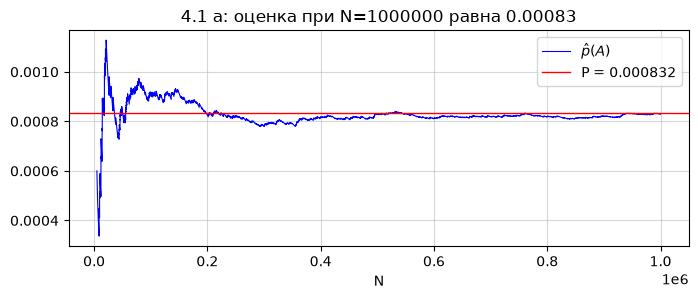

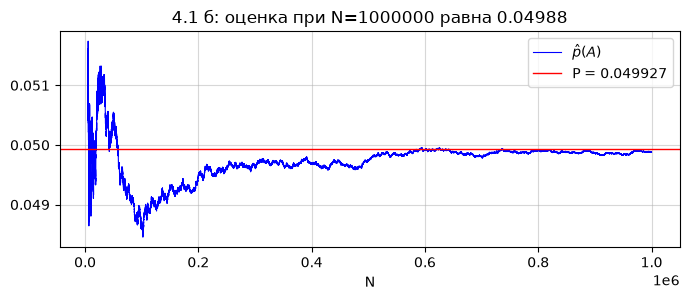

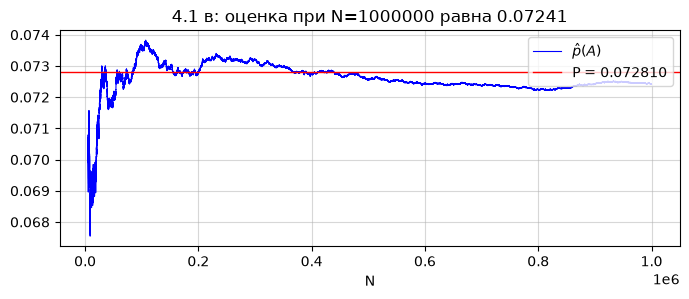

с возвращением: P(A)=0.00358995, P(B)=0.050427, P(D)=0.093383


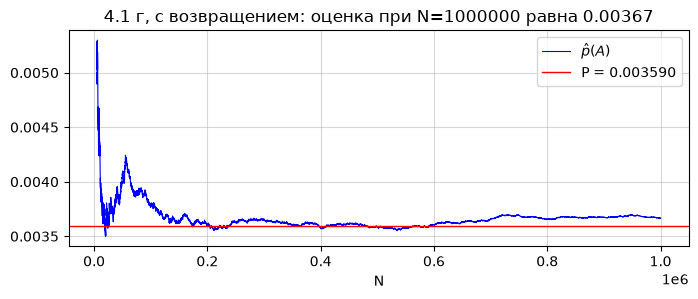

In [2]:
total = comb(23,6)
PA,PB,PD = F(comb(9,6),total),F(comb(6,3)*comb(8,2)*9,total),F(comb(8,4)*comb(15,2),total)
print('без возвращения:',PA,float(PA),'|',PB,float(PB),'|',PD,float(PD))
assert PA==F(4,4807)
N = 1000000
# Симуляция по цепочке: число шаров цвета в выборке без возвращения
balls = np.array([0]*8+[1]*6+[2]*9)  # 0 — белый, 1 — синий, 2 — красный
keys = rng.random((N,23)); draw = balls[np.argpartition(keys,6,axis=1)[:,:6]]
w,b,r = (draw==0).sum(1),(draw==1).sum(1),(draw==2).sum(1)
evA,evB,evD = r==6,(b==3)&(w==2)&(r==1),w==4
for ev,P,name in ((evA,PA,'4.1 а'),(evB,PB,'4.1 б'),(evD,PD,'4.1 в')):
    check(freq_plot(ev,float(P),name,'Sol_4_1' if name.endswith('а') else None,skip=5000),float(P),N)
pw,pb,pr = 8/23,6/23,9/23
PA_r = pr**6; PB_r = 60*pb**3*pw**2*pr; PD_r = comb(6,4)*pw**4*(1-pw)**2
print(f'с возвращением: P(A)={PA_r:.8f}, P(B)={PB_r:.6f}, P(D)={PD_r:.6f}')
check(0.00358549,PA_r,10**6)   # значение из листка — статистическая оценка, она согласуется с точным
draw_r = rng.choice(3,size=(N,6),p=[pw,pb,pr])
check(freq_plot((draw_r==2).all(1),PA_r,'4.1 г, с возвращением',skip=5000),PA_r,N)

**4.2.** 5 мужчин и 5 женщин рассаживаются в ряд. $A$ — никакие две женщины не сидят рядом, $B$ — все мужчины рядом.

Важны только места женщин: всего $C_{10}^5=252$ равновероятных набора.

**A.** Пять женщин ставим в промежутки между пятью мужчинами: $C_6^5=6$ способов, $P(A)=\dfrac{6}{252}=\dfrac1{42}$.

**B.** Блок из пяти мужчин занимает одну из $6$ позиций, $P(B)=\dfrac{6}{252}=\dfrac1{42}$.

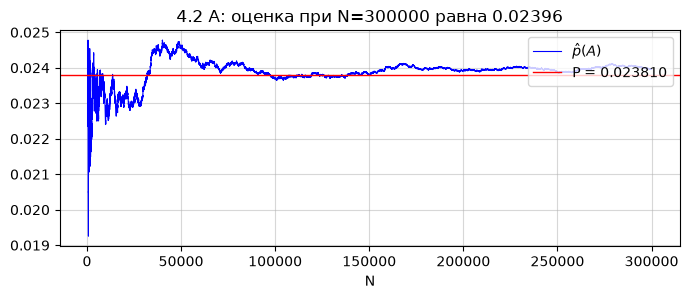

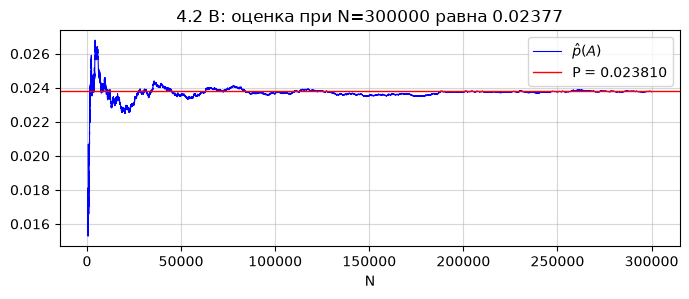

In [3]:
N = 300000
seat = np.argsort(rng.random((N,10)),axis=1)<5   # True — женщина на этом месте
evA = ~(seat[:,1:]&seat[:,:-1]).any(1)
men = ~seat; first = men.argmax(1); last = 9-men[:,::-1].argmax(1); evB = last-first==4
for ev,nm in ((evA,'4.2 A'),(evB,'4.2 B')): check(freq_plot(ev,1/42,nm),1/42,N)

**4.3.** Симметричную монету бросают до первого герба; $A$ — не более пяти бросаний. $P(\bar A)=(1/2)^5$, поэтому $P(A)=\dfrac{31}{32}=0{,}96875$.

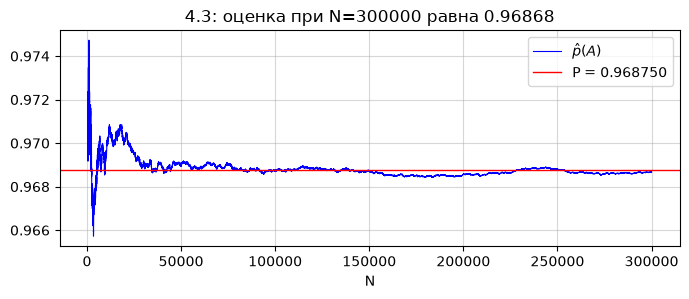

In [4]:
N = 300000; check(freq_plot(rng.geometric(.5,N)<=5,31/32,'4.3'),31/32,N)

**4.4–4.5.** Монету с $P(\text{герб})=p$ бросают, пока дважды подряд не выпадет одна сторона.

**Модель.** $\Omega=\{\omega_n^{Г},\omega_n^{Р}:n\geqslant2\}$, где $\omega_n$ — последовательность длины $n$, первые $n-1$ бросков которой чередуются, а последний совпадает с предпоследним. Индекс обозначает сторону, выпавшую дважды. При $q=1-p$ для $n=2k$ существует две такие последовательности:
$$P(n=2k)=p^{k+1}q^{k-1}+q^{k+1}p^{k-1}=(pq)^{k-1}(p^2+q^2),$$
а для $n=2k+1$ получаем $P(n=2k+1)=p^kq^k\cdot q+q^kp^k\cdot p=(pq)^k$. Сумма всех вероятностей равна $1$: $\dfrac{p^2+q^2}{1-pq}+\dfrac{pq}{1-pq}=\dfrac{(p+q)^2-pq}{1-pq}=1$.

**Чётное число бросаний:**
$$P_{\text{чёт}}=\sum_{k\geqslant1}(pq)^{k-1}(p^2+q^2)=\frac{p^2+q^2}{1-pq}.$$
При $p=\tfrac12$ получаем $\dfrac{1/2}{3/4}=\dfrac23$ (задача 4.4).

**Кратно 4** ($k=2m$):
$$P_4=\sum_{m\geqslant1}(pq)^{2m-1}(p^2+q^2)=\frac{(p^2+q^2)\,pq}{1-(pq)^2}.$$
При $p=0{,}7$: $P_{\text{чёт}}=\dfrac{0{,}58}{0{,}79}\approx0{,}73418$, $P_4=\dfrac{0{,}58\cdot0{,}21}{1-0{,}0441}\approx0{,}12742$.

0.5 чётное: 0.6666666666666666  кратно 4: 0.13333333333333333


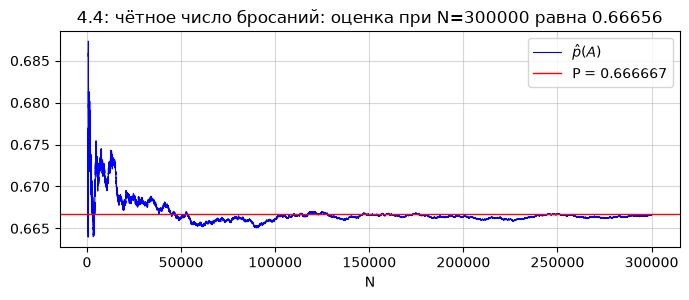

0.7 чётное: 0.7341772151898733  кратно 4: 0.1274191861073334


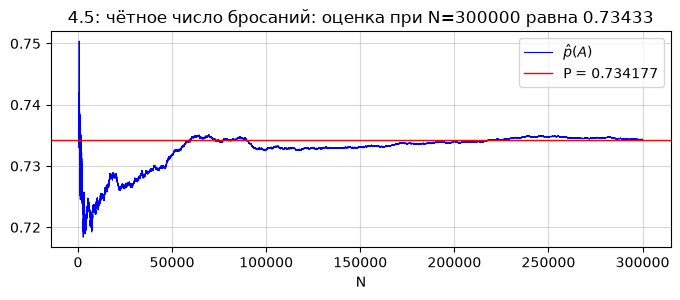

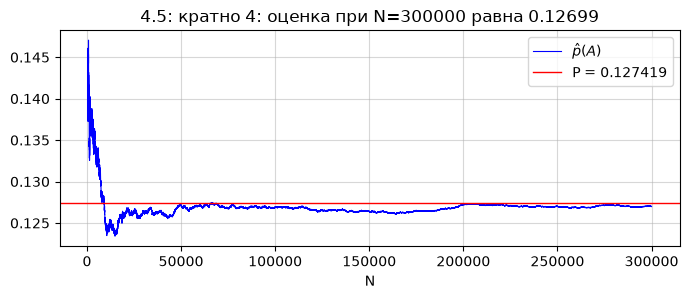

In [5]:
def tosses_until_repeat(p,N,maxlen=200):
    '''Число бросаний до первого совпадения двух соседних результатов.'''
    flips = rng.random((N,maxlen))<p
    same = flips[:,1:]==flips[:,:-1]
    return same.argmax(1)+2

def exact(p):
    q = 1-p; s = p*p+q*q
    return s/(1-p*q),s*p*q/(1-(p*q)**2)

N = 300000
for p,nm in ((.5,'4.4'),(.7,'4.5')):
    even,four = exact(p); L = tosses_until_repeat(p,N)
    print(p,'чётное:',even,' кратно 4:',four)
    check(freq_plot(L%2==0,even,f'{nm}: чётное число бросаний'),even,N)
    if p==.7: check(freq_plot(L%4==0,four,f'{nm}: кратно 4'),four,N)
assert np.isclose(exact(.5)[0],2/3)

**4.6.** Лицо $A$ ждёт $10$ мин, лицо $B$ — $12$ мин, время прихода равномерно в пределах часа. Пусть $x,y\in[0,60]$ — моменты прихода $A$ и $B$. Встреча состоится, если $-10\leqslant x-y\leqslant12$: когда первым пришёл $A$, $B$ должен успеть за $10$ мин; когда первым пришёл $B$, $A$ должен успеть за $12$ мин. Площадь дополнения состоит из двух треугольников с катетами $50$ и $48$:
$$P=1-\frac{50^2/2+48^2/2}{3600}=\frac{1198}{3600}\approx0{,}332778.$$

0.33277777777777773


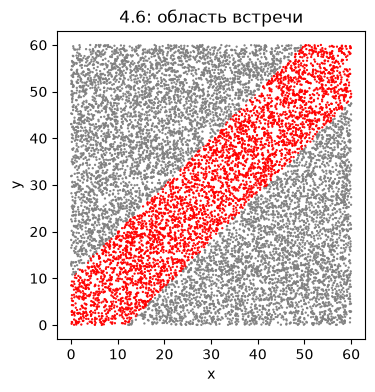

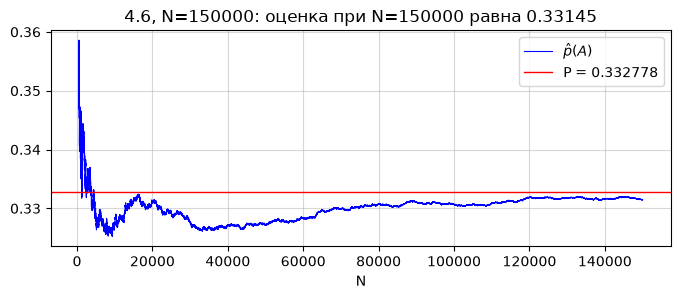

In [6]:
N = 150000
x,y = rng.uniform(0,60,(2,N))
ev = (y-x<=10)&(x-y<=12)   # если первым пришёл A (x<y), он ждёт 10 минут; если B — 12 минут
exact_p = 1-(50**2/2+48**2/2)/3600; print(exact_p); assert round(exact_p,6)==.332778
fig,ax = plt.subplots(figsize=(4,4)); ax.scatter(x[:12000],y[:12000],s=.4,c=np.where(ev[:12000],'r','gray')); ax.set_aspect('equal'); ax.set_title('4.6: область встречи'); ax.set_xlabel('x'); ax.set_ylabel('y')
fig.savefig('fig/Sol_4_6_region.png',dpi=120,bbox_inches='tight'); plt.show()
check(freq_plot(ev,exact_p,'4.6, N=150000','Sol_4_6'),exact_p,N)

**4.7.** Иван ($x$) и Пётр ($y$) приходят в момент из $[0,60]$ (минуты после 11:00), каждый ждёт до конца часа, но не более $15$ мин. Встреча происходит в момент $\max(x,y)$, если $|x-y|\leqslant15$.

- $A$ — встреча состоялась: $P(A)=1-\left(\tfrac{45}{60}\right)^2=\tfrac7{16}$.
- $B=\bar A$: $P(B)=\tfrac9{16}$.
- $C$ — Ивану не пришлось ждать Петра: Пётр уже на месте, когда приходит Иван, то есть $y\leqslant x\leqslant y+15$. $P(C)=\tfrac12P(A)=\tfrac7{32}$.
- $D$ — встреча после 11:30: $\max(x,y)>30$ при $|x-y|\leqslant15$. Площадь области встречи равна $1575$, внутри квадрата $[0,30]^2$ её часть равна $900-15^2=675$, поэтому $P(D)=\tfrac{900}{3600}=\tfrac14$.
- $E$ — Иван опоздал на встречу: он пришёл, когда Пётр уже ушёл, то есть $x>y+15$. $P(E)=\tfrac12\left(\tfrac{45}{60}\right)^2=\tfrac9{32}$.
- $F$ — встреча состоялась, когда до конца часа оставалось меньше $5$ мин: $\max(x,y)>55$. Внутри $[0,55]^2$ часть области встречи равна $55^2-40^2=1425$, поэтому $P(F)=\tfrac{1575-1425}{3600}=\tfrac1{24}$.

*Формулировки $C$ и $E$ в листке допускают другое прочтение: «Иван пришёл позже Петра». В этом случае обе вероятности равнялись бы $\tfrac12$. Здесь выбрано прочтение с учётом того, что Пётр ждёт только $15$ мин.*

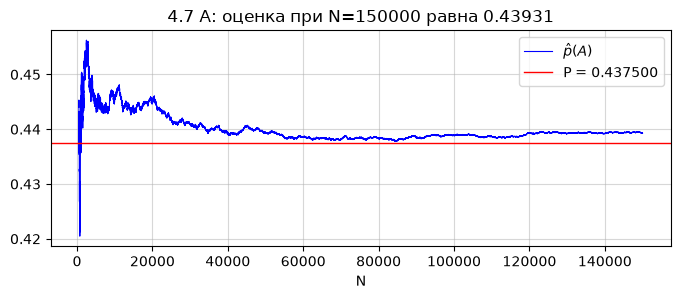

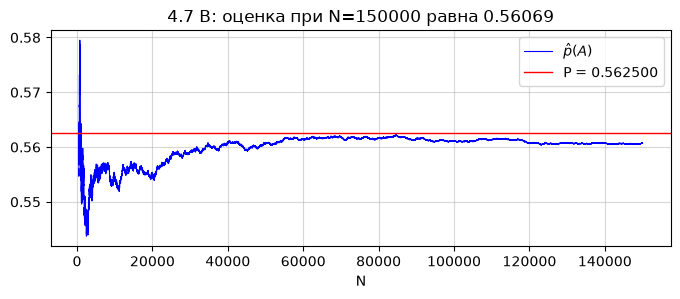

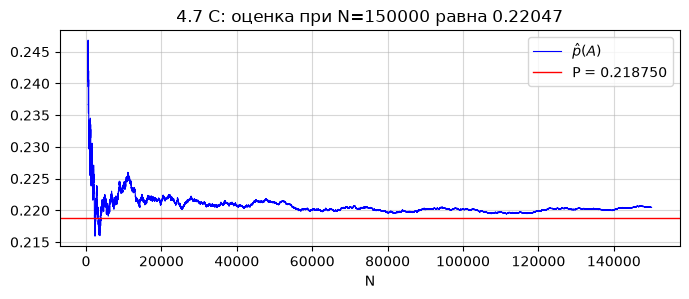

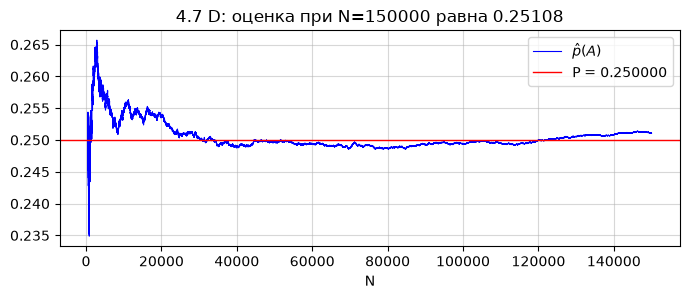

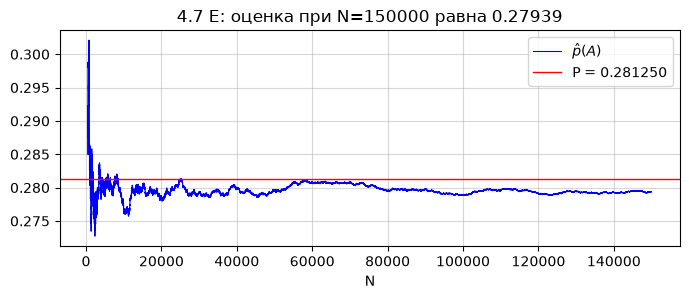

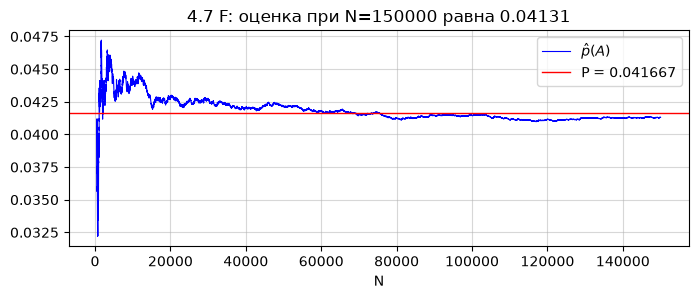

In [7]:
N = 150000
x,y = rng.uniform(0,60,(2,N)); meet = abs(x-y)<=15; t = np.maximum(x,y)
ev7 = {'A':(meet,7/16),'B':(~meet,9/16),'C':((y<=x)&(x<=y+15),7/32),'D':(meet&(t>30),1/4),'E':(x>y+15,9/32),'F':(meet&(t>55),1/24)}
for k,(ev,P) in ev7.items():
    check(freq_plot(ev,P,f'4.7 {k}'),P,N)

**4.8.** На $[a,b]$ выбирается $x$, затем на $[a,x]$ выбирается $y$. Положим $a=0$, $b=1$: это не меняет вероятностей. Условная вероятность: $y$ равномерно на $[0,x]$.

- $A$ — вторая точка ближе к $b$, чем первая к $a$: $1-y<x$, то есть $y>1-x$.
$$P(A)=\int_{1/2}^1\frac{x-(1-x)}{x}\,dx=\int_{1/2}^1\left(2-\frac1x\right)dx=1-\ln2\approx0{,}30685.$$
- $B$ — расстояние между точками меньше половины отрезка: $x-y<\tfrac12$. При $x\leqslant\tfrac12$ это выполнено всегда, при $x>\tfrac12$ условная вероятность равна $\dfrac{1}{2x}$:
$$P(B)=\frac12+\int_{1/2}^1\frac{dx}{2x}=\frac{1+\ln2}{2}\approx0{,}84657.$$
- $C$ — первая точка ближе ко второй, чем к $b$: $x-y<1-x$, то есть $y>2x-1$. При $x\leqslant\tfrac12$ это выполнено всегда, при $x>\tfrac12$ условная вероятность равна $\dfrac{1-x}{x}$:
$$P(C)=\frac12+\int_{1/2}^1\left(\frac1x-1\right)dx=\ln2\approx0{,}69315.$$

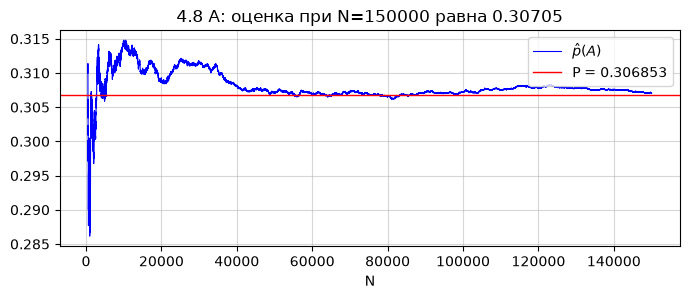

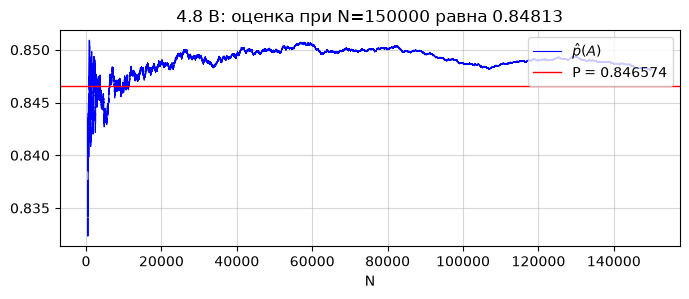

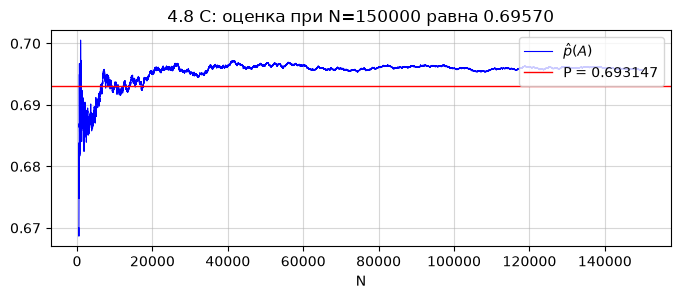

In [8]:
N = 150000
x = rng.random(N); y = x*rng.random(N)
for ev,P,nm in ((y>1-x,1-np.log(2),'A'),(x-y<.5,(1+np.log(2))/2,'B'),(x-y<1-x,np.log(2),'C')):
    check(freq_plot(ev,P,f'4.8 {nm}'),P,N)

**4.9.** Отрезок $[0;1]$ делится на 3 части. Найти вероятность, что из них можно сложить остроугольный треугольник.

Пусть длины равны $l_1,l_2,l_3$, $l_1+l_2+l_3=1$; точка $(l_1,l_2)$ равномерна в треугольнике площади $\tfrac12$. Треугольник остроугольный тогда и только тогда, когда для каждой стороны $l_i^2<l_j^2+l_k^2$ (при этом неравенство треугольника выполняется автоматически).

Рассмотрим событие $O_3=\{l_3^2\geqslant l_1^2+l_2^2\}$. Подставив $l_3=1-l_1-l_2$, получаем $l_2\leqslant\dfrac{1-2l_1}{2(1-l_1)}$, $l_1\in[0,\tfrac12]$. Его площадь:
$$\int_0^{1/2}\frac{1-2l}{2(1-l)}\,dl=\int_0^{1/2}\left(1-\frac{1}{2(1-l)}\right)dl=\frac12-\frac{\ln2}{2},$$
то есть $P(O_3)=1-\ln2$. События $O_1,O_2,O_3$ попарно несовместны (самая длинная сторона одна), поэтому
$$P(A)=1-3(1-\ln2)=3\ln2-2\approx0{,}0794415.$$

0.07944154167983575


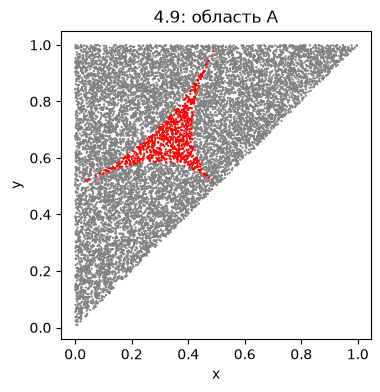

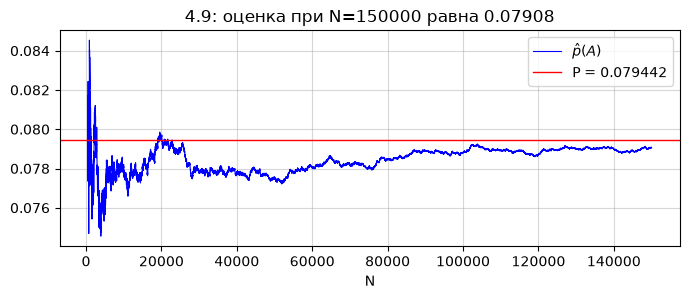

In [9]:
N = 150000
u = np.sort(rng.random((N,2)),axis=1); L = np.c_[u[:,0],u[:,1]-u[:,0],1-u[:,1]]
L2 = L**2; ev = (2*L2.max(1)<(L2).sum(1))
P = 3*np.log(2)-2; print(P); assert abs(P-0.0794415417)<1e-9
fig,ax = plt.subplots(figsize=(4,4)); ax.scatter(u[:12000,0],u[:12000,1],s=.4,c=np.where(ev[:12000],'r','gray')); ax.set_aspect('equal'); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title('4.9: область A')
fig.savefig('fig/Sol_4_9_region.png',dpi=120,bbox_inches='tight'); plt.show()
check(freq_plot(ev,P,'4.9','Sol_4_9'),P,N)

**4.10.** В круге радиуса $1$ наудачу выбирается отрезок (концы — две независимые равномерные точки). Найти вероятность, что его длина меньше $1$.

Плотность длины $d$ для двух точек в единичном круге известна:
$$f(d)=\frac{4d}{\pi}\left(\arccos\frac d2-\frac d2\sqrt{1-\frac{d^2}{4}}\right),\quad 0\leqslant d\leqslant2.$$
Она получается из площади пересечения двух единичных кругов с центрами на расстоянии $d$. Интегрируя от $0$ до $1$, получаем $P=1-\dfrac{3\sqrt3}{4\pi}\approx0{,}5865033$.

0.9999999999952974 0.5865033284336559 0.5865033284336559


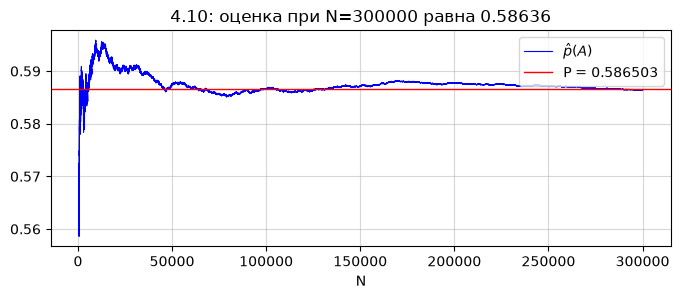

In [10]:
f = lambda d:4*d/np.pi*(np.arccos(d/2)-d/2*np.sqrt(1-d*d/4))
total = quad(f,0,2)[0]; P_int = quad(f,0,1)[0]; P = 1-3*np.sqrt(3)/(4*np.pi)
print(total,P_int,P); assert np.isclose(total,1) and np.isclose(P_int,P)

def in_disk(N):
    r = np.sqrt(rng.random(N)); t = rng.uniform(0,2*np.pi,N); return r*np.cos(t),r*np.sin(t)
N = 300000
x1,y1 = in_disk(N); x2,y2 = in_disk(N)
check(freq_plot(np.hypot(x1-x2,y1-y2)<1,P,'4.10'),P,N)

**4.11.** $n$ лиц, момент прихода равномерен на часе, каждый ждёт $q$ (доля часа). Доказать, что $P_n=nq^{n-1}-(n-1)q^n$.

**Доказательство.** Встреча состоится тогда и только тогда, когда размах $R=\max t_i-\min t_i\leqslant q$. Выбираем, кто пришёл первым ($n$ способов). При его времени $t$ остальные должны попасть в $[t,\min(t+q,1)]$:
$$P_n=n\int_0^1\left(\min(q,1-t)\right)^{n-1}dt=n\left[(1-q)q^{n-1}+\int_{1-q}^1(1-t)^{n-1}dt\right]=n(1-q)q^{n-1}+q^n=nq^{n-1}-(n-1)q^n.$$
Проверка: при $n=2$ получаем $2q-q^2=1-(1-q)^2$, что верно; при $n=3$ получаем $3q^2-2q^3$.

**По крайней мере двое ($n=3$).** Встречи нет, если все соседние разности в упорядоченных моментах больше $q$. Вероятность этого равна $(1-2q)^3$ при $q<\tfrac12$ (сдвиг упорядоченных моментов). Значит, $P=1-(1-2q)_+^3$.

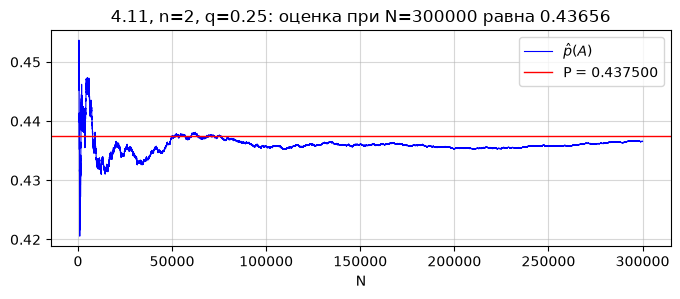

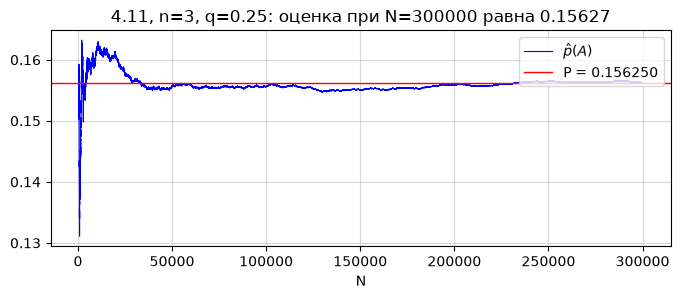

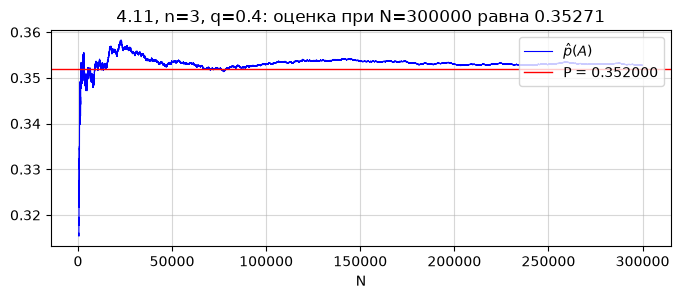

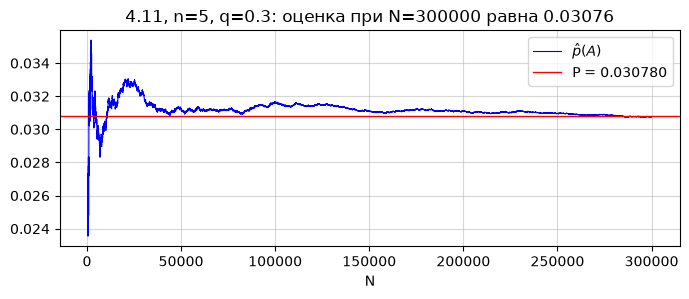

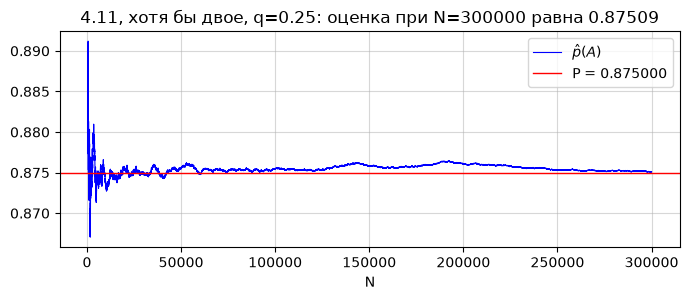

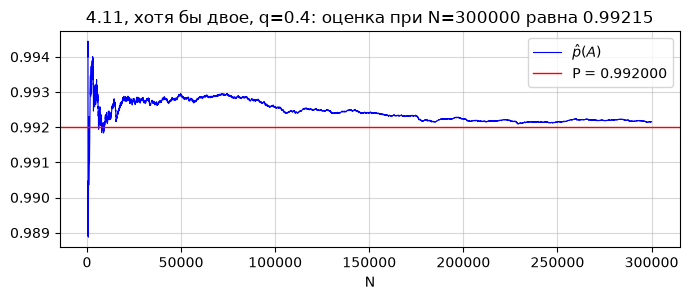

In [11]:
N = 300000
for k,q in ((2,.25),(3,.25),(3,.4),(5,.3)):
    t = rng.random((N,k)); P = k*q**(k-1)-(k-1)*q**k
    check(freq_plot(np.ptp(t,axis=1)<=q,P,f'4.11, n={k}, q={q}'),P,N)
for q in (.25,.4):
    t = np.sort(rng.random((N,3)),axis=1); ev = (np.diff(t,axis=1)<=q).any(1); P = 1-max(1-2*q,0)**3
    check(freq_plot(ev,P,f'4.11, хотя бы двое, q={q}'),P,N)

**4.12.\*\*** Время ожидания $w_1\leqslant w_2\leqslant\dots\leqslant w_n$ (в формулах листка предполагается именно такой порядок).

**Общая формула.** Пусть последним приходит лицо $i$ в момент $t$. Встреча состоится, если каждое лицо $j\ne i$ пришло в интервале $[t-w_j,t]$. Таким образом,
$$P_n=\sum_{i=1}^n\int_0^1\prod_{j\ne i}\min(w_j,t)\,dt.$$
Для $n=2$ получаем $\displaystyle\int_0^1\min(w_2,t)\,dt+\int_0^1\min(w_1,t)\,dt=1-\frac{(1-w_1)^2}{2}-\frac{(1-w_2)^2}{2}$, что и требовалось. Для $n=3,4$ интеграл кусочно-полиномиальный и точно вычислен ниже, результат совпадает с формулами листка.

In [12]:
w1,w2,w3,w4,t = sp.symbols('w1 w2 w3 w4 t',positive=True)

def integral_of_product(ws):
    '''∫_0^1 ∏ min(w,t) dt при упорядоченных w, разбиение отрезка по точкам w.'''
    pts = [0,*ws,1]; total = 0
    for k in range(len(pts)-1):
        expr = 1
        for i,w in enumerate(ws):
            expr *= t if i>=k else w    # на k-м отрезке первые k значений меньше t
        total += sp.integrate(expr,(t,pts[k],pts[k+1]))
    return sp.expand(total)

def P_general(ws):
    return sp.expand(sum(integral_of_product(ws[:i]+ws[i+1:]) for i in range(len(ws))))

P2,P3,P4 = P_general([w1,w2]),P_general([w1,w2,w3]),P_general([w1,w2,w3,w4])
assert sp.expand(P2-(1-(1-w1)**2/2-(1-w2)**2/2))==0
f3 = w1*w2+w1*w3+w2*w3-(w1*w2**2+w1*w3**2+w2*w3**2)/2-w1**3/3-w2**3/6
assert sp.expand(P3-f3)==0
f4 = w1*w2*w3+w1*w2*w4+w1*w3*w4+w2*w3*w4-w4**2/2*(w1*w2+w1*w3+w2*w3)-w3**3/6*(w1+w2)-w1*w2*w3**2/2-w1*w2**3/3-w1**4/4-w2**4/12
print('P4 - формула листка =',sp.simplify(P4-f4))
val = P3.subs({w1:sp.Rational(1,4),w2:sp.Rational(1,3),w3:sp.Rational(1,2)}); print('c) P3 =',val,'=',float(val)); assert val==sp.Rational(1435,5184)

P4 - формула листка = 0
c) P3 = 1435/5184 = 0.2768132716049383


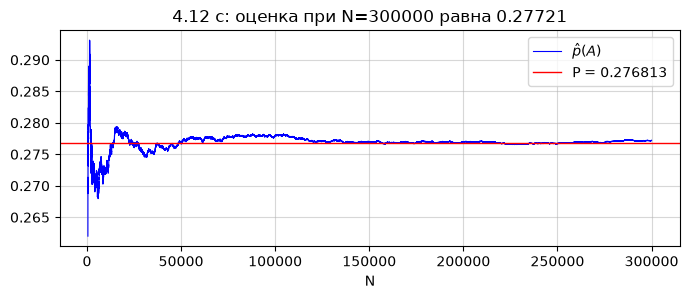

P4 (интеграл) = 0.04168750000000001  формула листка = 0.04168750000000001  МК = 0.0417155


In [13]:
# Монте-Карло для случая c) и проверка формулы P4
def meet_prob_ev(ws,N):
    arr = rng.random((N,len(ws))); ws = np.array(ws)
    return arr.max(1)<=(arr+ws).min(1)    # кто-то ещё ждёт каждого, пока приходит последний

N = 300000
check(freq_plot(meet_prob_ev([.25,1/3,.5],N),1435/5184,'4.12 c','Sol_4_12'),1435/5184,N)
vals = {w1:.1,w2:.2,w3:.3,w4:.45}
print('P4 (интеграл) =',float(P4.subs(vals)),' формула листка =',float(f4.subs(vals)),' МК =',meet_prob_ev([.1,.2,.3,.45],2000000).mean())

**4.13.** В корзину с $n$ шарами (число белых $X\sim\operatorname{Bin}(n,p)$) опускают белый шар. Найти вероятность извлечь белый.

По формуле полной вероятности
$$P=E\left[\frac{X+1}{n+1}\right]=\frac{np+1}{n+1}.$$
При $n=10$, $p=\tfrac13$ получаем $\dfrac{10/3+1}{11}=\dfrac{13}{33}\approx0{,}3939$.

**Важно.** В листке напечатан ответ $0{,}15625$. Он не согласуется с условием: формула и моделирование дают $0{,}3939$. По-видимому, в листке ошибка, например ответ от другой задачи или с другими данными. Стоит уточнить это у преподавателя.

0.3939393939393939 0.39318


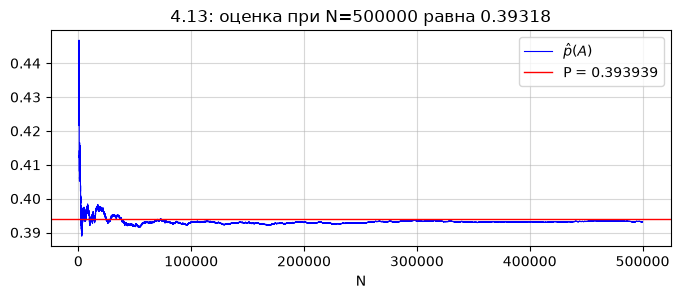

In [14]:
N = 500000
X = rng.binomial(10,1/3,N); ev = rng.random(N)<(X+1)/11
P = 13/33; print(P,ev.mean()); check(freq_plot(ev,P,'4.13'),P,N)

**4.14.** В первой корзине 6 шаров, белых $\operatorname{Bin}(3;0{,}8)$; во второй 11 шаров, белых $\operatorname{Bin}(4;0{,}7)$. Все шары перекладывают в третью корзину (17 шаров). Найти $P(A)$ и $P(H|A)$.

Математические ожидания числа белых равны $2{,}4$ и $2{,}8$, поэтому $P(A)=\dfrac{5{,}2}{17}\approx0{,}3059$. Шар белый и из первой корзины с вероятностью $\dfrac{2{,}4}{17}$, откуда $P(H|A)=\dfrac{2{,}4}{5{,}2}\approx0{,}4615$.

0.3058823529411765 0.4615384615384615


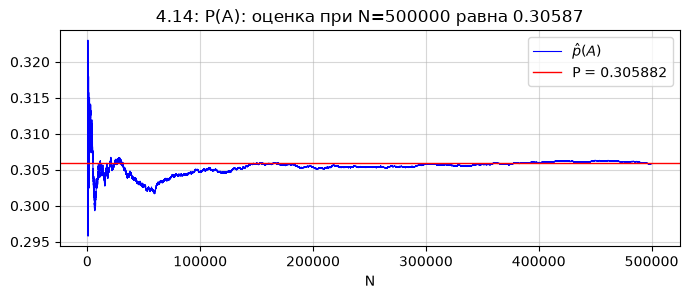

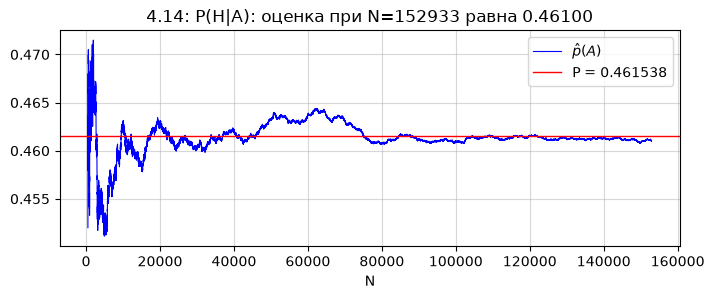

In [15]:
N = 500000
W1 = rng.binomial(3,.8,N); W2 = rng.binomial(4,.7,N)
pick = rng.integers(0,17,N)
white = (pick<W1)|((pick>=6)&(pick<6+W2)); from_first = pick<6
print(5.2/17,2.4/5.2); assert round(5.2/17,4)==.3059 and round(2.4/5.2,4)==.4615
check(freq_plot(white,5.2/17,'4.14: P(A)'),5.2/17,N)
check(freq_plot(from_first[white],2.4/5.2,'4.14: P(H|A)'),2.4/5.2,white.sum())

**4.15–4.17.** Метод Монте-Карло. *В листках сказано «округляя до одного знака», а в ответах напечатаны два знака. Сравниваем с двумя.*

**4.15.** Прямоугольник $|x|\leqslant20$, $|y|\leqslant8$. $A$: расстояние между точками меньше $11$; $B$: $|x_1-x_2|<14$.

P(A)=0.371, P(A|B)=0.640 (листок: 0.37; 0.64)


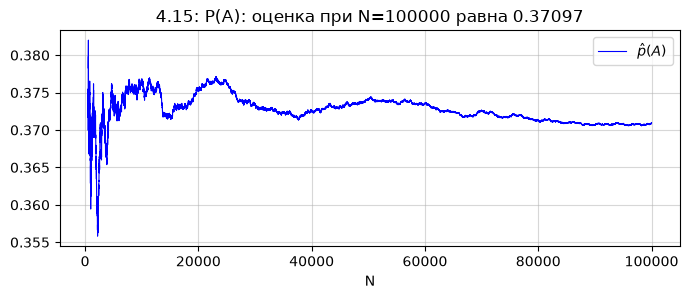

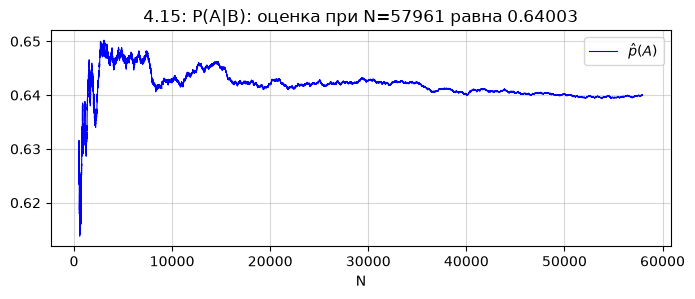

In [16]:
N = 100000
p1 = rng.uniform([-20,-8],[20,8],(N,2)); p2 = rng.uniform([-20,-8],[20,8],(N,2))
A = np.hypot(*(p1-p2).T)<11; B = abs(p1[:,0]-p2[:,0])<14
print(f'P(A)={A.mean():.3f}, P(A|B)={A[B].mean():.3f} (листок: 0.37; 0.64)')
assert abs(A.mean()-.37)<.01 and abs(A[B].mean()-.64)<.01
freq_plot(A,None,'4.15: P(A)'); freq_plot(A[B],None,'4.15: P(A|B)');

**4.16.** Эллипс $(u/23)^2+(v/6)^2\leqslant1$. $A$: расстояние меньше $9{,}2$; $B$: координаты первой точки больше $0$, координаты второй меньше $0$. Равномерная точка в эллипсе получается как $(23r\cos t,\ 6r\sin t)$, где $r=\sqrt\xi$.

P(A)=0.352, P(A|B)=0.067, пар в B: 6182 (листок: 0.35; 0.07)


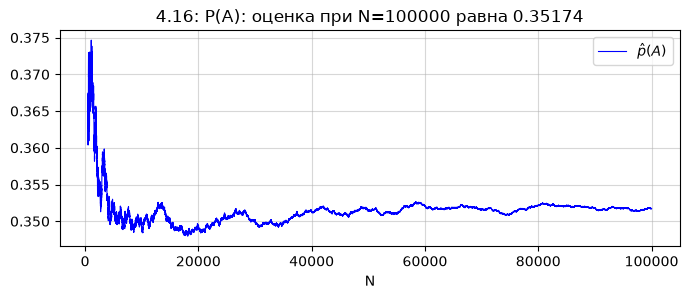

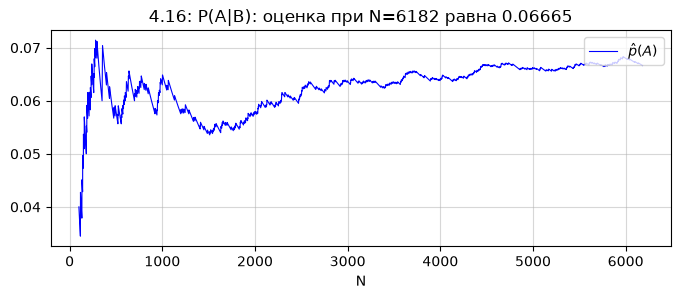

In [17]:
def in_ellipse(N):
    r = np.sqrt(rng.random(N)); t = rng.uniform(0,2*np.pi,N); return np.c_[23*r*np.cos(t),6*r*np.sin(t)]
N = 100000
e1,e2 = in_ellipse(N),in_ellipse(N)
A = np.hypot(*(e1-e2).T)<9.2; B = (e1>0).all(1)&(e2<0).all(1)
print(f'P(A)={A.mean():.3f}, P(A|B)={A[B].mean():.3f}, пар в B: {B.sum()} (листок: 0.35; 0.07)')
assert abs(A.mean()-.35)<.01 and abs(A[B].mean()-.07)<.02
freq_plot(A,None,'4.16: P(A)'); freq_plot(A[B],None,'4.16: P(A|B)',skip=100);

**4.17.** Точки $A,B,C$ случайны в единичном кубе; $R$: наименьший угол меньше $26{,}7°$; $S$: наибольший угол меньше $81{,}9°$; $T$: треугольник остроугольный. По указанию получаем $100000$ остроугольных треугольников.

остроугольных: 100000  доля: 0.45782
P(R|T)=0.112, P(S|T)=0.654 (листок: 0.11; 0.65)


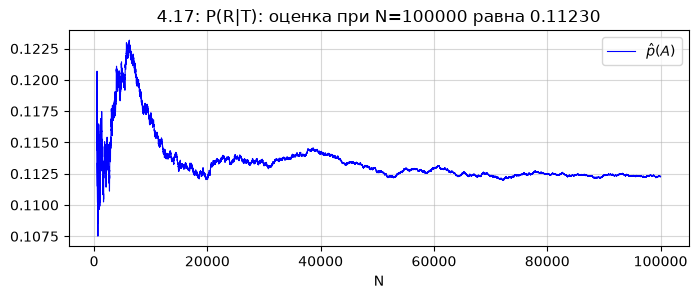

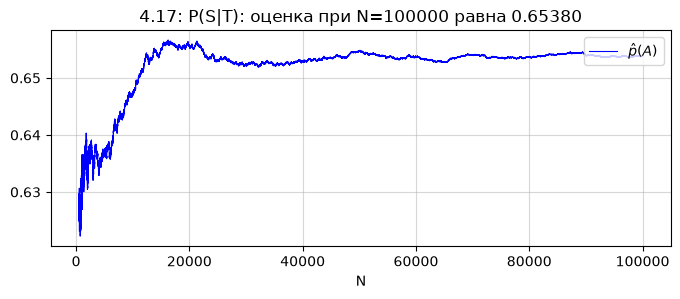

In [18]:
def angles(P):
    a,b,c = P[:,0],P[:,1],P[:,2]
    ang = lambda u,v:np.degrees(np.arccos(np.clip((u*v).sum(1)/np.linalg.norm(u,axis=1)/np.linalg.norm(v,axis=1),-1,1)))
    return np.c_[ang(b-a,c-a),ang(a-b,c-b),ang(a-c,b-c)]

An = angles(rng.random((300000,3,3)))
assert np.allclose(An.sum(1),180)
acute = An[An.max(1)<90][:100000]; print('остроугольных:',len(acute),' доля:',(An.max(1)<90).mean())
R,S = acute.min(1)<26.7,acute.max(1)<81.9
print(f'P(R|T)={R.mean():.3f}, P(S|T)={S.mean():.3f} (листок: 0.11; 0.65)')
assert abs(R.mean()-.11)<.01 and abs(S.mean()-.65)<.01
freq_plot(R,None,'4.17: P(R|T)'); freq_plot(S,None,'4.17: P(S|T)');